# Gaussian Replace 递归训练复现

复现 Kazdan 等人的 [Collapse or Thrive: Perils and Promises of Synthetic Data in a Self-Generating World](https://proceedings.mlr.press/v267/kazdan25a.html)（ICML 2025，第 2.1 节与图 1 中的 Replace 实验）。

运行环境需要 NumPy、pandas、Matplotlib、Seaborn 和 SciPy。按顺序运行全部代码单元，结果保存到相对目录 `results/`。本实现的协方差估计采用分母 $n$。

本 notebook 保留已有实验数值和图像输出，历史输出中的本机绝对路径已隐去。


In [1]:
# ============================================================
# 导入需要的包，并建立结果保存目录
# ============================================================

import os
import time
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt



warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)


# ============================================================
# 结果保存目录
# ============================================================

RESULT_DIR = "results"

os.makedirs(
    RESULT_DIR,
    exist_ok=True
)

print("=" * 70)
print("结果保存目录：")
print(os.path.abspath(RESULT_DIR))
print("=" * 70)

结果保存目录：
<本地结果目录>


In [2]:
# ============================================================
# 实验参数
# ============================================================


# ------------------------------------------------------------
# 高维 Gaussian 维数
# ------------------------------------------------------------

DATA_DIM = 100


# ------------------------------------------------------------
# 每一轮训练 / 生成的样本数量
# ------------------------------------------------------------

SAMPLE_SIZES = [
    10,
    32,
    100,
    316,
    1000
]


# ------------------------------------------------------------
# 递归训练轮数
# ------------------------------------------------------------

NUM_ITERATIONS = 100


# ------------------------------------------------------------
# Monte Carlo 重复次数
#
# 共 100 个 seeds
# ------------------------------------------------------------

SEEDS = list(
    range(100)
)


# ------------------------------------------------------------
# 初始真实 Gaussian
#
# mu_0 = 0
# Sigma_0 = sigma^2 I_d
#
# 这里 sigma^2 = 1
# ------------------------------------------------------------

SIGMA_SQUARED = 1.0


# ------------------------------------------------------------
# 打印实验参数
# ------------------------------------------------------------

print("=" * 70)
print("高维 Gaussian 递归训练实验")
print("=" * 70)

print("Dimension d =", DATA_DIM)
print("Sample sizes =", SAMPLE_SIZES)
print("Iterations =", NUM_ITERATIONS)
print("Seeds =", f"{SEEDS[0]} ~ {SEEDS[-1]}")
print("Number of seeds =", len(SEEDS))
print("Sigma squared =", SIGMA_SQUARED)

print("\nTotal recursive runs =",
      len(SAMPLE_SIZES) * len(SEEDS))

高维 Gaussian 递归训练实验
Dimension d = 100
Sample sizes = [10, 32, 100, 316, 1000]
Iterations = 100
Seeds = 0 ~ 99
Number of seeds = 100
Sigma squared = 1.0

Total recursive runs = 500


In [3]:
# ============================================================
# 保存实验配置
# ============================================================

config_df = pd.DataFrame({

    "Parameter": [
        "Data Dimension",
        "Sample Sizes",
        "Num Iterations",
        "Num Seeds",
        "Seed Range",
        "Sigma Squared",
        "Recursive Setting",
        "Covariance Estimator"
    ],

    "Value": [
        DATA_DIM,
        str(SAMPLE_SIZES),
        NUM_ITERATIONS,
        len(SEEDS),
        f"{SEEDS[0]}-{SEEDS[-1]}",
        SIGMA_SQUARED,
        "Replace",
        "np.cov(..., bias=True)"
    ]
})


config_path = os.path.join(
    RESULT_DIR,
    "experiment_config.csv"
)


config_df.to_csv(
    config_path,
    index=False
)


display(config_df)

print("\nSaved:")
print(config_path)

,Parameter,Value
0,Data Dimension,100
1,Sample Sizes,"[10, 32, 100, 316, 1000]"
2,Num Iterations,100
3,Num Seeds,100
4,Seed Range,0-99
5,Sigma Squared,1.0
6,Recursive Setting,Replace
7,Covariance Estimator,"np.cov(..., bias=True)"



Saved:
<本地结果目录>/experiment_config.csv


In [4]:
# ============================================================
# Gaussian 参数估计
# ============================================================

def fit_mean_and_cov_from_data(data):

    # --------------------------------------------------------
    # 样本均值
    # --------------------------------------------------------

    mu = np.mean(
        data,
        axis=0
    )


    # --------------------------------------------------------
    # 样本协方差
    #
    # 与论文官方代码保持一致：
    #
    # bias=True
    #
    # 即分母使用 n
    # --------------------------------------------------------

    Sigma = np.cov(
        data,
        rowvar=False,
        bias=True
    )


    # --------------------------------------------------------
    # 防止 d=1 时 np.cov 返回 scalar
    # --------------------------------------------------------

    if data.shape[1] == 1:

        Sigma = np.reshape(
            Sigma,
            newshape=(1, 1)
        )


    return mu, Sigma

In [5]:
# ============================================================
# 两个核心定量指标
# ============================================================


def compute_metrics(
    fit_mean,
    fit_cov,
    init_mean,
    init_cov
):

    # ========================================================
    # 1. Mean Drift
    #
    # ||mu_hat_t - mu_0||_2^2
    # ========================================================

    mean_drift = np.sum(
        np.square(
            fit_mean
            -
            init_mean
        )
    )


    # ========================================================
    # 2. Covariance Trace Ratio
    #
    # Tr(Sigma_hat_t)
    # ----------------
    # Tr(Sigma_0)
    # ========================================================

    cov_trace_ratio = (
        np.trace(fit_cov)
        /
        np.trace(init_cov)
    )


    return (
        mean_drift,
        cov_trace_ratio
    )


In [6]:
# ============================================================
# Replace-only recursive Gaussian experiment
# ============================================================


def run_replace_experiment(
    data_dim,
    num_samples_per_iteration,
    num_iterations,
    sigma_squared,
    seed
):


    np.random.seed(
        seed
    )


    # ========================================================
    # Initial true Gaussian
    #
    # mu_0 = 0
    # Sigma_0 = sigma^2 I_d
    # ========================================================

    init_mean = np.zeros(
        data_dim
    )


    init_cov = (
        sigma_squared
        *
        np.eye(data_dim)
    )


    # ========================================================
    # Initial real dataset
    #
    # D_0 ~ N(0, I_d)
    # ========================================================

    all_data = np.random.multivariate_normal(
        mean=init_mean,
        cov=init_cov,
        size=num_samples_per_iteration
    )


    rows = []


    # ========================================================
    # Recursive training
    # ========================================================

    for iteration_idx in range(
        1,
        num_iterations + 1
    ):

        # ====================================================
        # Step 1:
        # Fit Gaussian to current data
        # ====================================================

        fit_mean, fit_cov = (
            fit_mean_and_cov_from_data(
                all_data
            )
        )


        # ====================================================
        # Step 2:
        # Compute two quantitative metrics
        # ====================================================

        (
            mean_drift,
            cov_trace_ratio

        ) = compute_metrics(
            fit_mean=fit_mean,
            fit_cov=fit_cov,
            init_mean=init_mean,
            init_cov=init_cov
        )


        # ====================================================
        # Step 3:
        # Save current generation
        # ====================================================

        rows.append({

            "Data Dimension":
                data_dim,

            "Num Samples per Iteration":
                num_samples_per_iteration,

            "Model-Fitting Iteration":
                iteration_idx,

            "Seed":
                seed,

            "Squared Error of Fit Mean":
                mean_drift,

            "Trace of Fit Cov / Trace of Init Cov":
                cov_trace_ratio
        })


        # ====================================================
        # Step 4:
        # Generate new synthetic dataset
        #
        # D_{t+1} ~ N(mu_hat_t, Sigma_hat_t)
        # ====================================================

        new_data = np.random.multivariate_normal(
            mean=fit_mean,
            cov=fit_cov,
            size=num_samples_per_iteration
        )


        # ====================================================
        # Step 5:
        # Replace: completely discard old dataset
        # ====================================================

        all_data = new_data


    return pd.DataFrame(
        rows
    )


In [7]:
# ============================================================
# Full Monte Carlo experiment
#
# d = 100
#
# n = 10, 32, 100, 316, 1000
#
# seeds = 0,...,99
#
# Replace only
# ============================================================


all_results = []


total_runs = (
    len(SAMPLE_SIZES)
    *
    len(SEEDS)
)


run_counter = 0


start_time = time.time()


for n in SAMPLE_SIZES:


    print("\n")
    print("=" * 75)

    print(
        f"Running n = {n}"
    )

    print("=" * 75)


    for seed in SEEDS:


        run_counter += 1


        # ----------------------------------------------------
        # 打印运行进度
        # ----------------------------------------------------

        if (
            seed % 10 == 0
            or
            seed == SEEDS[-1]
        ):


            elapsed = (
                time.time()
                -
                start_time
            )


            print(

                f"Run {run_counter}/{total_runs}"

                f" | n={n}"

                f" | seed={seed}"

                f" | elapsed={elapsed/60:.2f} min"
            )


        # ----------------------------------------------------
        # Run one recursive chain
        # ----------------------------------------------------

        result = run_replace_experiment(

            data_dim=DATA_DIM,

            num_samples_per_iteration=n,

            num_iterations=NUM_ITERATIONS,

            sigma_squared=SIGMA_SQUARED,

            seed=seed
        )


        all_results.append(
            result
        )


# ============================================================
# Combine
# ============================================================

raw_results = pd.concat(

    all_results,

    ignore_index=True
)


elapsed = (
    time.time()
    -
    start_time
)


print("\n")
print("=" * 75)
print("MONTE CARLO FINISHED")
print("=" * 75)

print(
    f"Total time = {elapsed/60:.2f} minutes"
)

print(
    "raw_results shape =",
    raw_results.shape
)


display(
    raw_results.head()
)



Running n = 10
Run 1/500 | n=10 | seed=0 | elapsed=0.00 min
Run 11/500 | n=10 | seed=10 | elapsed=0.02 min
Run 21/500 | n=10 | seed=20 | elapsed=0.04 min
Run 31/500 | n=10 | seed=30 | elapsed=0.06 min
Run 41/500 | n=10 | seed=40 | elapsed=0.08 min
Run 51/500 | n=10 | seed=50 | elapsed=0.10 min
Run 61/500 | n=10 | seed=60 | elapsed=0.12 min
Run 71/500 | n=10 | seed=70 | elapsed=0.14 min
Run 81/500 | n=10 | seed=80 | elapsed=0.16 min
Run 91/500 | n=10 | seed=90 | elapsed=0.18 min
Run 100/500 | n=10 | seed=99 | elapsed=0.20 min


Running n = 32
Run 101/500 | n=32 | seed=0 | elapsed=0.20 min
Run 111/500 | n=32 | seed=10 | elapsed=0.22 min
Run 121/500 | n=32 | seed=20 | elapsed=0.25 min
Run 131/500 | n=32 | seed=30 | elapsed=0.27 min
Run 141/500 | n=32 | seed=40 | elapsed=0.29 min
Run 151/500 | n=32 | seed=50 | elapsed=0.31 min
Run 161/500 | n=32 | seed=60 | elapsed=0.33 min
Run 171/500 | n=32 | seed=70 | elapsed=0.36 min
Run 181/500 | n=32 | seed=80 | elapsed=0.38 min
Run 191/500 | n=32 

,Data Dimension,Num Samples per Iteration,Model-Fitting Iteration,Seed,Squared Error of Fit Mean,Trace of Fit Cov / Trace of Init Cov
0,100,10,1,0,10.360668,0.872676
1,100,10,2,0,18.323710,0.639848
2,100,10,3,0,53.548272,0.474888
3,100,10,4,0,64.678132,0.503770
4,100,10,5,0,53.210770,0.536252


In [8]:
# ============================================================
# Save raw results
# ============================================================


raw_path = os.path.join(

    RESULT_DIR,

    "raw_results_d100_replace.csv"
)


raw_results.to_csv(

    raw_path,

    index=False
)


print("Raw results saved:")

print(
    raw_path
)


print(
    "\nFile size:"
)


print(

    round(

        os.path.getsize(
            raw_path
        )

        /

        1024**2,

        3
    ),

    "MB"
)

Raw results saved:
<本地结果目录>/raw_results_d100_replace.csv

File size:
2.463 MB


In [9]:
# ============================================================
# Monte Carlo summary
# ============================================================

summary_results = (

    raw_results

    .groupby([
        "Data Dimension",
        "Num Samples per Iteration",
        "Model-Fitting Iteration"
    ])

    .agg({
        "Squared Error of Fit Mean":
            ["mean", "std"],

        "Trace of Fit Cov / Trace of Init Cov":
            ["mean", "std"]
    })

    .reset_index()
)


# ============================================================
# Flatten column names
# ============================================================

summary_results.columns = [

    "_".join(
        [
            str(x)
            for x in col
            if str(x) != ""
        ]
    )

    if isinstance(col, tuple)

    else col

    for col in summary_results.columns
]


print(
    summary_results.columns.tolist()
)

display(
    summary_results.head()
)


['Data Dimension', 'Num Samples per Iteration', 'Model-Fitting Iteration', 'Squared Error of Fit Mean_mean', 'Squared Error of Fit Mean_std', 'Trace of Fit Cov / Trace of Init Cov_mean', 'Trace of Fit Cov / Trace of Init Cov_std']


,Data Dimension,Num Samples per Iteration,Model-Fitting Iteration,Squared Error of Fit Mean_mean,Squared Error of Fit Mean_std,Trace of Fit Cov / Trace of Init Cov_mean,Trace of Fit Cov / Trace of Init Cov_std
0,100,10,1,9.954488,1.334885,0.899219,0.042813
1,100,10,2,18.079227,3.901696,0.825381,0.141591
2,100,10,3,27.433716,9.296237,0.744814,0.216461
3,100,10,4,34.631661,14.488434,0.688585,0.289508
4,100,10,5,40.791566,18.509802,0.624701,0.348644


In [10]:
# ============================================================
# Save summary results
# ============================================================


summary_path = os.path.join(

    RESULT_DIR,

    "summary_results_d100_replace.csv"
)


summary_results.to_csv(

    summary_path,

    index=False
)


print(
    "Summary saved:"
)

print(
    summary_path
)

Summary saved:
<本地结果目录>/summary_results_d100_replace.csv


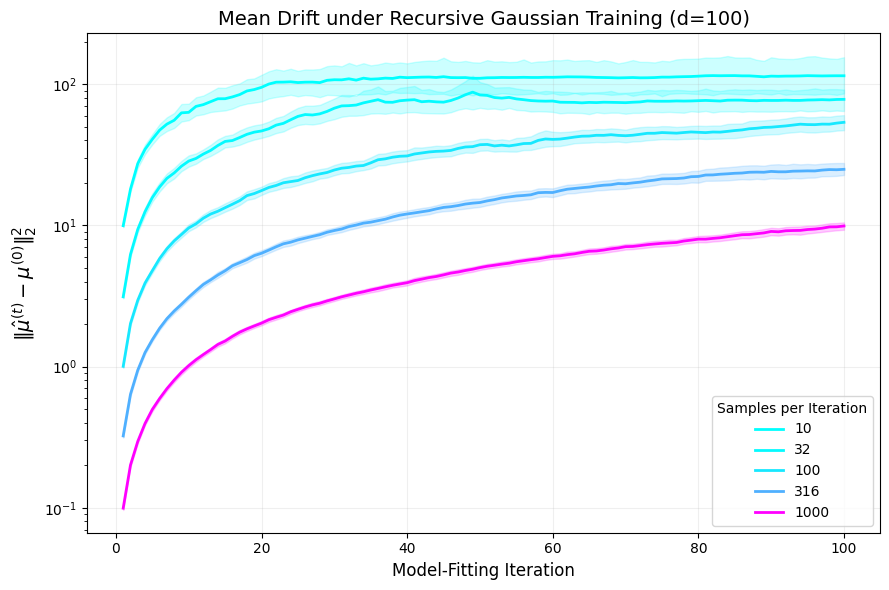

Figure saved:
<本地结果目录>/figure1_mean_drift.png


In [11]:
# ============================================================
# FINAL FIGURE 1
#
# Mean Drift
# ============================================================

import seaborn as sns
import matplotlib.pyplot as plt
import os


# ------------------------------------------------------------
# 只取当前 d=100 实验
# ------------------------------------------------------------

plot_data = raw_results[
    raw_results["Data Dimension"] == DATA_DIM
].copy()


# ------------------------------------------------------------
# 画图
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))


ax = sns.lineplot(
    data=plot_data,
    x="Model-Fitting Iteration",
    y="Squared Error of Fit Mean",
    hue="Num Samples per Iteration",
    palette="cool",
    estimator="mean",
    errorbar=("ci", 95),
    n_boot=1000,
    linewidth=2.0
)



ax.set_yscale("log")


# ------------------------------------------------------------
# 坐标轴
# ------------------------------------------------------------

ax.set_xlabel(
    "Model-Fitting Iteration",
    fontsize=12
)


ax.set_ylabel(
    r"$\|\hat{\mu}^{(t)}-\mu^{(0)}\|_2^2$",
    fontsize=14
)


ax.set_title(
    "Mean Drift under Recursive Gaussian Training (d=100)",
    fontsize=14
)


# ------------------------------------------------------------
# Legend
# ------------------------------------------------------------

ax.legend(
    title="Samples per Iteration"
)


# ------------------------------------------------------------
# Grid
# ------------------------------------------------------------

ax.grid(
    alpha=0.20
)


plt.tight_layout()


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

mean_fig_path = os.path.join(
    RESULT_DIR,
    "figure1_mean_drift.png"
)


plt.savefig(
    mean_fig_path,
    dpi=300,
    bbox_inches="tight"
)


plt.show()


print("Figure saved:")
print(mean_fig_path)

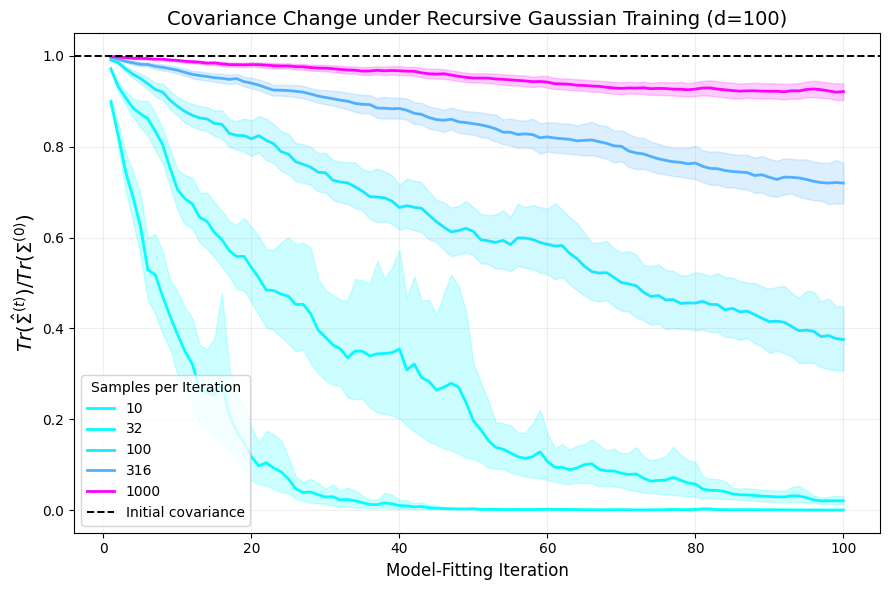

Figure saved:
<本地结果目录>/figure2_covariance_change.png


In [12]:
# ============================================================
# FINAL FIGURE 2
#
# Covariance Change
#
# 中间实线：
#   100 seeds Monte Carlo mean
#
# 周围浅色区域：
#   95% confidence interval
# ============================================================

import seaborn as sns
import matplotlib.pyplot as plt
import os


# ------------------------------------------------------------
# d=100 raw results
# ------------------------------------------------------------

plot_data = raw_results[
    raw_results["Data Dimension"] == DATA_DIM
].copy()


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))


ax = sns.lineplot(
    data=plot_data,
    x="Model-Fitting Iteration",
    y="Trace of Fit Cov / Trace of Init Cov",
    hue="Num Samples per Iteration",
    palette="cool",
    estimator="mean",
    errorbar=("ci", 95),
    n_boot=1000,
    linewidth=2.0
)


# ------------------------------------------------------------
# 原始 covariance reference
#
# Tr(Sigma_0) / Tr(Sigma_0) = 1
# ------------------------------------------------------------

ax.axhline(
    y=1.0,
    color="black",
    linestyle="--",
    linewidth=1.4,
    label="Initial covariance"
)


# ------------------------------------------------------------
# 坐标轴
# ------------------------------------------------------------

ax.set_xlabel(
    "Model-Fitting Iteration",
    fontsize=12
)


ax.set_ylabel(
    r"$Tr(\hat{\Sigma}^{(t)})/Tr(\Sigma^{(0)})$",
    fontsize=14
)


ax.set_title(
    "Covariance Change under Recursive Gaussian Training (d=100)",
    fontsize=14
)


# ------------------------------------------------------------
# Legend
# ------------------------------------------------------------

ax.legend(
    title="Samples per Iteration"
)


# ------------------------------------------------------------
# Grid
# ------------------------------------------------------------

ax.grid(
    alpha=0.20
)


plt.tight_layout()


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

cov_fig_path = os.path.join(
    RESULT_DIR,
    "figure2_covariance_change.png"
)


plt.savefig(
    cov_fig_path,
    dpi=300,
    bbox_inches="tight"
)


plt.show()


print("Figure saved:")
print(cov_fig_path)

Marginal Gaussian PDF Visualization
Data dimension d = 100
Samples per iteration n = 316
Seed = 0
Selected fixed dimension = 85
Iterations = 100

First 5 iterations:


,Model-Fitting Iteration,Dimension,Marginal Mean,Marginal Variance,Marginal Std
0,1,85,-0.017817,1.006976,1.003482
1,2,85,-0.072348,1.006232,1.003111
2,3,85,0.033018,0.991679,0.995831
3,4,85,-0.030200,0.902439,0.949968
4,5,85,-0.030670,0.930032,0.964382



Last 5 iterations:


,Model-Fitting Iteration,Dimension,Marginal Mean,Marginal Variance,Marginal Std
95,96,85,-0.494952,0.372169,0.610056
96,97,85,-0.467325,0.401003,0.633248
97,98,85,-0.540531,0.397057,0.630125
98,99,85,-0.540658,0.366659,0.605523
99,100,85,-0.522464,0.399660,0.632187



Marginal history saved:
<本地结果目录>/marginal_pdf_history_d100_n316_dim85.csv

PDF x range = [-4.207, 4.016]


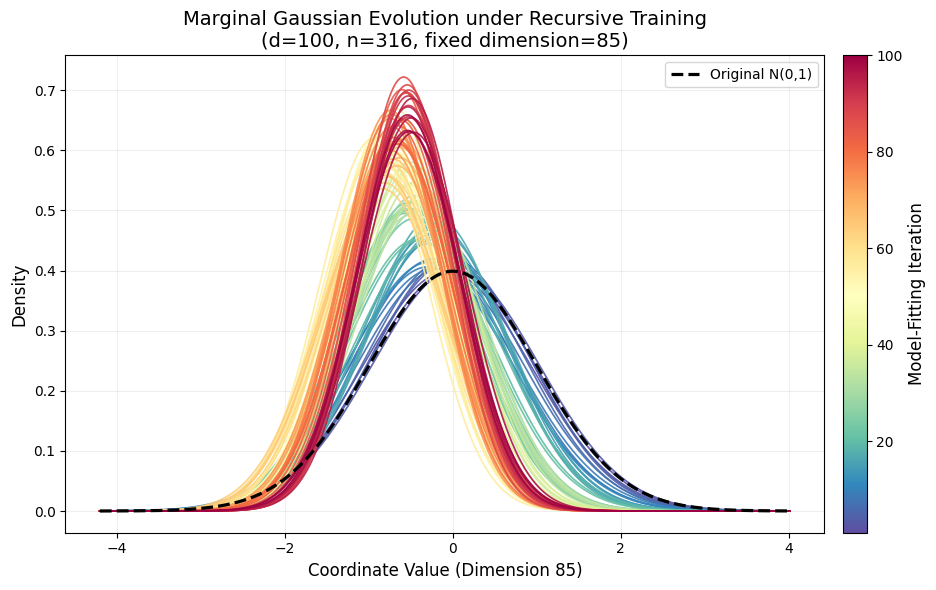


FIGURE 3 FINISHED

Selected dimension:
85

Marginal parameter history:
<本地结果目录>/marginal_pdf_history_d100_n316_dim85.csv

PNG figure:
<本地结果目录>/figure3_marginal_gaussian_pdf.png

PDF figure:
<本地结果目录>/figure3_marginal_gaussian_pdf.pdf


In [13]:
# ============================================================
# FINAL FIGURE 3
#
# Marginal Gaussian Evolution under Recursive Training
#
# 实验设置：
#   d = 100
#   n = 316
#   seed = 0
#   Replace-only recursive training
#
# 目的：
#   从 100 个维度中随机选择一个维度，并固定该维度。
#   绘制 t = 1,...,100 每一轮该维度的 marginal Gaussian PDF。
#
#   整个递归训练仍然发生在 d=100 的高维 Gaussian 中，
#   这里只取其中一个坐标维度的一维边缘分布进行可视化。
#
#   X_j^(t) ~ N(mu_t[j], Sigma_t[j,j])
#
# 画图方式参考论文：
#   1. 每一轮都画 PDF
#   2. 使用 Spectral_r 渐变色
#   3. 右侧 colorbar 表示 Model-Fitting Iteration
#   4. 原始 N(0,1) 用黑色虚线表示
# ============================================================


from scipy.stats import norm
import matplotlib.pyplot as plt
import matplotlib
import numpy as np
import pandas as pd
import os


# ============================================================
# 1. 参数设置
# ============================================================

PDF_N = 316
PDF_SEED = 0


# ------------------------------------------------------------
# 从 d=100 个维度中随机选择一个维度
#
# 注意：
# 这里只随机一次。
# 后面 t=1,...,100 始终观察这个固定维度。
# ------------------------------------------------------------

rng_dim = np.random.default_rng(0)

PLOT_DIM = int(
    rng_dim.integers(
        0,
        DATA_DIM
    )
)


print("=" * 70)
print("Marginal Gaussian PDF Visualization")
print("=" * 70)

print("Data dimension d =", DATA_DIM)
print("Samples per iteration n =", PDF_N)
print("Seed =", PDF_SEED)
print("Selected fixed dimension =", PLOT_DIM)
print("Iterations =", NUM_ITERATIONS)


# ============================================================
# 2. 初始化高维 Gaussian
#
# 原始真实分布：
#
# X^(0) ~ N(0, I_100)
#
# 因此任意一个坐标的 marginal distribution 都是：
#
# X_j^(0) ~ N(0,1)
# ============================================================

np.random.seed(
    PDF_SEED
)


init_mean = np.zeros(
    DATA_DIM
)


init_cov = (
    SIGMA_SQUARED
    *
    np.eye(DATA_DIM)
)


# ------------------------------------------------------------
# 从原始真实 Gaussian 生成第一批真实数据
# ------------------------------------------------------------

all_data = np.random.multivariate_normal(
    mean=init_mean,
    cov=init_cov,
    size=PDF_N
)


# ============================================================
# 3. 运行一条 d=100 的 Replace recursion
#
# 每一轮：
#
# D_t
#   ↓
# fit Gaussian
#   ↓
# (mu_hat_t, Sigma_hat_t)
#   ↓
# 记录固定维度：
#
# mu_hat_t[j]
# Sigma_hat_t[j,j]
#
#   ↓
# 生成新的 synthetic dataset
#   ↓
# D_{t+1}
#
# ============================================================

pdf_history = []


for iteration_idx in range(
    1,
    NUM_ITERATIONS + 1
):

    # --------------------------------------------------------
    # Step 1
    # 用当前数据拟合 d=100 Gaussian
    # --------------------------------------------------------

    fit_mean, fit_cov = (
        fit_mean_and_cov_from_data(
            all_data
        )
    )


    # --------------------------------------------------------
    # Step 2
    # 取固定维度 j 的 marginal mean
    #
    # mu_t[j]
    # --------------------------------------------------------

    marginal_mean = float(
        fit_mean[
            PLOT_DIM
        ]
    )


    # --------------------------------------------------------
    # Step 3
    # 取固定维度 j 的 marginal variance
    #
    # Sigma_t[j,j]
    # --------------------------------------------------------

    marginal_variance = float(
        fit_cov[
            PLOT_DIM,
            PLOT_DIM
        ]
    )


    # --------------------------------------------------------
    # marginal standard deviation
    #
    # sqrt(Sigma_t[j,j])
    # --------------------------------------------------------

    marginal_std = np.sqrt(
        max(
            marginal_variance,
            0
        )
    )


    # --------------------------------------------------------
    # 保存当前 iteration 的 marginal 参数
    # --------------------------------------------------------

    pdf_history.append({

        "Model-Fitting Iteration":
            iteration_idx,

        "Dimension":
            PLOT_DIM,

        "Marginal Mean":
            marginal_mean,

        "Marginal Variance":
            marginal_variance,

        "Marginal Std":
            marginal_std
    })


    # --------------------------------------------------------
    # Step 4
    # 从当前拟合的 d=100 Gaussian 中
    # 生成下一代 synthetic data
    #
    # D_{t+1}
    # ~
    # N(mu_hat_t, Sigma_hat_t)
    # --------------------------------------------------------

    new_data = np.random.multivariate_normal(
        mean=fit_mean,
        cov=fit_cov,
        size=PDF_N
    )


    # --------------------------------------------------------
    # Step 5
    # Replace
    #
    # 完全丢弃上一代数据
    # --------------------------------------------------------

    all_data = new_data


# ============================================================
# 4. 转成 DataFrame
# ============================================================

pdf_history = pd.DataFrame(
    pdf_history
)


print("\nFirst 5 iterations:")

display(
    pdf_history.head()
)


print("\nLast 5 iterations:")

display(
    pdf_history.tail()
)


# ============================================================
# 5. 保存每一轮 marginal 参数
# ============================================================

pdf_history_path = os.path.join(
    RESULT_DIR,
    f"marginal_pdf_history_d{DATA_DIM}_n{PDF_N}_dim{PLOT_DIM}.csv"
)


pdf_history.to_csv(
    pdf_history_path,
    index=False
)


print("\nMarginal history saved:")
print(pdf_history_path)


# ============================================================
# 6. 建立绘制 Gaussian PDF 的横坐标
#
# 根据 100 轮中所有 mean 和 std 自动确定范围，
# 同时至少覆盖 [-4,4]。
# ============================================================

all_means = pdf_history[
    "Marginal Mean"
].values


all_stds = pdf_history[
    "Marginal Std"
].values


x_min = min(
    -4.0,
    np.min(
        all_means
        -
        4.0 * all_stds
    )
)


x_max = max(
    4.0,
    np.max(
        all_means
        +
        4.0 * all_stds
    )
)


x = np.linspace(
    x_min,
    x_max,
    1500
)


print(
    f"\nPDF x range = [{x_min:.3f}, {x_max:.3f}]"
)


# ============================================================
# 7. 设置 colormap
# ============================================================

cmap = matplotlib.colormaps[
    "Spectral_r"
]


norm_color = matplotlib.colors.Normalize(
    vmin=1,
    vmax=NUM_ITERATIONS
)


# ============================================================
# 8. 创建最终图
# ============================================================

fig, ax = plt.subplots(
    figsize=(10, 6)
)


# ============================================================
# 9. 画原始真实 marginal Gaussian
#
# 原始：
#
# X ~ N(0, I_100)
#
# 因此固定维度：
#
# X_j ~ N(0,1)
#
# 黑色虚线作为 reference
# ============================================================

original_pdf = norm.pdf(
    x,
    loc=0.0,
    scale=np.sqrt(
        SIGMA_SQUARED
    )
)


ax.plot(
    x,
    original_pdf,
    color="black",
    linestyle="--",
    linewidth=2.3,
    label="Original N(0,1)",
    zorder=100
)


# ============================================================
# 10. 绘制 t = 1,...,100 的全部 marginal Gaussian PDFs
#
# 每一轮：
#
# X_j^(t)
# ~
# N(
#     mu_hat_t[j],
#     Sigma_hat_t[j,j]
# )
#
# ============================================================

for _, row in pdf_history.iterrows():

    # --------------------------------------------------------
    # 当前 iteration
    # --------------------------------------------------------

    iteration_idx = int(
        row[
            "Model-Fitting Iteration"
        ]
    )


    # --------------------------------------------------------
    # 当前 marginal mean
    # --------------------------------------------------------

    mu_t = float(
        row[
            "Marginal Mean"
        ]
    )


    # --------------------------------------------------------
    # 当前 marginal variance
    # --------------------------------------------------------

    variance_t = float(
        row[
            "Marginal Variance"
        ]
    )


    # --------------------------------------------------------
    # variance -> standard deviation
    #
    # 加一个极小值避免数值问题
    # --------------------------------------------------------

    std_t = np.sqrt(
        max(
            variance_t,
            1e-12
        )
    )


    # --------------------------------------------------------
    # 当前 iteration 的 marginal Gaussian PDF
    #
    # f_t(x)
    # =
    # 1 / sqrt(2*pi*variance_t)
    #
    # *
    #
    # exp(
    # -(x-mu_t)^2 / (2*variance_t)
    # )
    # --------------------------------------------------------

    y = norm.pdf(
        x,
        loc=mu_t,
        scale=std_t
    )


    # --------------------------------------------------------
    # 根据 iteration 决定颜色
    # --------------------------------------------------------

    color = cmap(
        norm_color(
            iteration_idx
        )
    )


    # --------------------------------------------------------
    # 绘制
    #
    # 因为一共 100 条曲线，
    # 所以 linewidth 设置得稍细。
    # --------------------------------------------------------

    ax.plot(
        x,
        y,
        color=color,
        linewidth=1.25,
        alpha=0.90
    )


# ============================================================
# 11. 添加 Colorbar
#
# Colorbar 表示：
#
# 颜色 <-> Model-Fitting Iteration
# ============================================================

sm = matplotlib.cm.ScalarMappable(
    cmap=cmap,
    norm=norm_color
)


sm.set_array([])


cbar = fig.colorbar(
    sm,
    ax=ax,
    orientation="vertical",
    pad=0.02
)


cbar.set_label(
    "Model-Fitting Iteration",
    fontsize=12
)


# ============================================================
# 12. 坐标轴
# ============================================================

ax.set_xlabel(
    f"Coordinate Value (Dimension {PLOT_DIM})",
    fontsize=12
)


ax.set_ylabel(
    "Density",
    fontsize=12
)


# ============================================================
# 13. 标题
# ============================================================

ax.set_title(
    "Marginal Gaussian Evolution under Recursive Training\n"
    f"(d={DATA_DIM}, n={PDF_N}, fixed dimension={PLOT_DIM})",
    fontsize=14
)


# ============================================================
# 14. Legend
#
# 这里只标记 Original N(0,1)
#
# t=1,...,100 不需要全部放进 legend，
# 因为右侧 colorbar 已经表示 iteration。
# ============================================================

ax.legend(
    loc="upper right"
)


# ============================================================
# 15. 网格
# ============================================================

ax.grid(
    alpha=0.20
)


plt.tight_layout()


# ============================================================
# 16. 保存 PNG
# ============================================================

pdf_fig_png = os.path.join(
    RESULT_DIR,
    "figure3_marginal_gaussian_pdf.png"
)


plt.savefig(
    pdf_fig_png,
    dpi=300,
    bbox_inches="tight"
)


# ============================================================
# 17. 保存 PDF
# ============================================================

pdf_fig_pdf = os.path.join(
    RESULT_DIR,
    "figure3_marginal_gaussian_pdf.pdf"
)


plt.savefig(
    pdf_fig_pdf,
    bbox_inches="tight"
)


# ============================================================
# 18. 显示
# ============================================================

plt.show()


# ============================================================
# 19. 输出保存位置
# ============================================================

print("\n" + "=" * 70)
print("FIGURE 3 FINISHED")
print("=" * 70)

print("\nSelected dimension:")
print(PLOT_DIM)

print("\nMarginal parameter history:")
print(pdf_history_path)

print("\nPNG figure:")
print(pdf_fig_png)

print("\nPDF figure:")
print(pdf_fig_pdf)